# Experiment 10: Character, Digit, or Face Classification Using CNNs

**Student:** Harshit Dubey  
**Section:** C  
**Dataset:** MNIST handwritten digits  
**Framework:** PyTorch

## Aim

To design, train, and evaluate a Convolutional Neural Network for handwritten digit classification using the MNIST dataset.

## Purpose

CNNs learn hierarchical visual features directly from images. This experiment demonstrates preprocessing, CNN design, training, validation, testing, prediction, and standard classification metrics.

## Dataset and download

MNIST contains 60,000 training images and 10,000 test images of handwritten digits from 0 to 9. The `torchvision.datasets.MNIST` call below downloads the dataset into a local `data/` directory on first execution, so no manual dataset download is required.


## 1. Required libraries and reproducibility

The random seeds make the train/validation split and the reported sample predictions reproducible as far as the hardware and library versions permit.


In [8]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__}")
print(f"Device: {device}")

PyTorch: 2.14.0+cu130
Device: cpu


## 2. Load and preprocess MNIST

Images are converted to tensors and normalized using the MNIST mean and standard deviation. The training set is split into training and validation partitions; the official test set remains untouched until final evaluation.


Train images: 54,000
Validation images: 6,000
Test images: 10,000
Tensor batch shape: (128, 1, 28, 28)


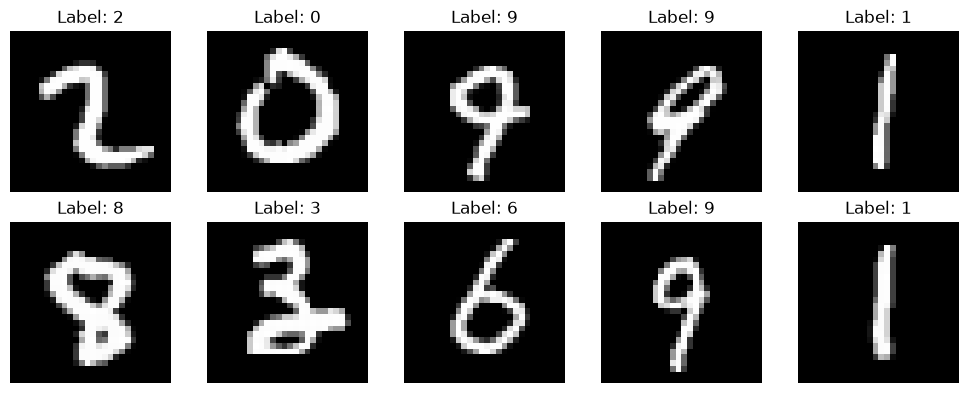

In [9]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_full = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="data", train=False, download=True, transform=transform)
train_size = int(0.9 * len(train_full))
validation_size = len(train_full) - train_size
train_dataset, validation_dataset = random_split(
    train_full,
    [train_size, validation_size],
    generator=torch.Generator().manual_seed(SEED)
)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
validation_loader = DataLoader(validation_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))
print(f"Train images: {len(train_dataset):,}")
print(f"Validation images: {len(validation_dataset):,}")
print(f"Test images: {len(test_dataset):,}")
print(f"Tensor batch shape: {tuple(images.shape)}")

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for axis, image, label in zip(axes.ravel(), images[:10], labels[:10]):
    axis.imshow(image.squeeze(), cmap="gray")
    axis.set_title(f"Label: {label.item()}")
    axis.axis("off")
plt.tight_layout()
plt.show()

## 3. CNN architecture

The network uses two convolutional blocks. Each block extracts local features with convolution, applies ReLU for non-linearity, and reduces spatial size with max pooling. The flattened feature vector is passed through fully connected layers and a 10-class output layer. Raw logits are used with cross-entropy loss; softmax is applied only when probabilities are needed.


In [10]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10)
        )

    def forward(self, inputs):
        return self.classifier(self.features(inputs))

model = DigitCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
print(model)
print(f"Trainable parameters: {sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad):,}")

DigitCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 421,642


## 4. Train the CNN

The Adam optimizer updates the weights, while cross-entropy compares the logits with the true digit labels. Validation loss and accuracy are recorded after every epoch to monitor generalization.


In [11]:
def run_epoch(data_loader, training=False):
    model.train(training)
    total_loss = 0.0
    correct = 0
    total = 0
    for batch_images, batch_labels in data_loader:
        batch_images, batch_labels = batch_images.to(device), batch_labels.to(device)
        if training:
            optimizer.zero_grad()
        logits = model(batch_images)
        loss = criterion(logits, batch_labels)
        if training:
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * batch_images.size(0)
        correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        total += batch_labels.size(0)
    return total_loss / total, correct / total

history = {"train_loss": [], "train_accuracy": [], "validation_loss": [], "validation_accuracy": []}
epochs = 3
for epoch in range(epochs):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    validation_loss, validation_accuracy = run_epoch(validation_loader)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_loss"].append(validation_loss)
    history["validation_accuracy"].append(validation_accuracy)
    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"train loss: {train_loss:.4f}, train accuracy: {train_accuracy:.4f} | "
        f"validation loss: {validation_loss:.4f}, validation accuracy: {validation_accuracy:.4f}"
    )

Epoch 1/3 | train loss: 0.2146, train accuracy: 0.9341 | validation loss: 0.0606, validation accuracy: 0.9837
Epoch 2/3 | train loss: 0.0616, train accuracy: 0.9808 | validation loss: 0.0519, validation accuracy: 0.9843
Epoch 3/3 | train loss: 0.0437, train accuracy: 0.9864 | validation loss: 0.0449, validation accuracy: 0.9870


## 5. Learning curves

The curves below show whether the model is learning and whether the validation performance follows the training performance.


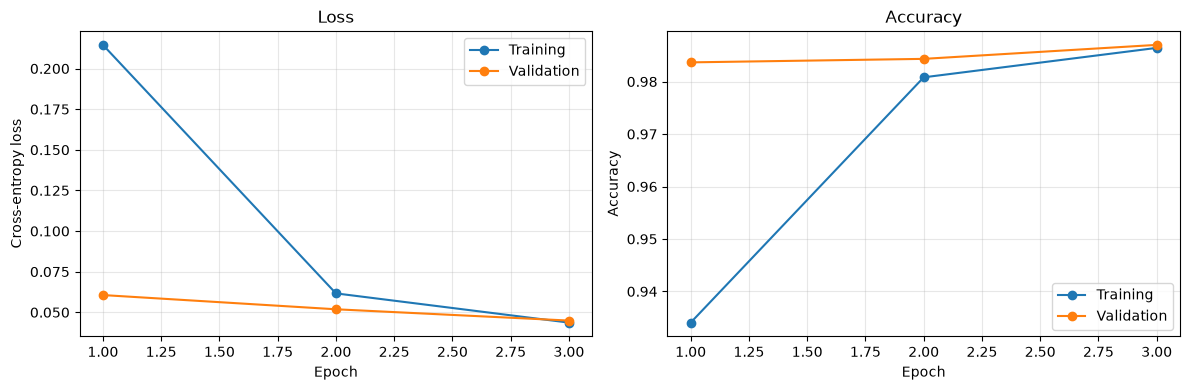

In [12]:
epochs_axis = range(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_axis, history["train_loss"], marker="o", label="Training")
axes[0].plot(epochs_axis, history["validation_loss"], marker="o", label="Validation")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(epochs_axis, history["train_accuracy"], marker="o", label="Training")
axes[1].plot(epochs_axis, history["validation_accuracy"], marker="o", label="Validation")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Test-set evaluation

Accuracy is the proportion of all correct predictions. Precision measures how many predictions for a class are correct, recall measures how many actual examples of a class are found, and F1-score is the harmonic mean of precision and recall. The confusion matrix shows the actual class against the predicted class.


Test accuracy: 0.9886 (98.86%)

Classification report:
              precision    recall  f1-score   support

           0     0.9819    0.9980    0.9899       980
           1     0.9973    0.9947    0.9960      1135
           2     0.9913    0.9942    0.9927      1032
           3     0.9920    0.9812    0.9866      1010
           4     0.9918    0.9868    0.9893       982
           5     0.9800    0.9899    0.9849       892
           6     0.9989    0.9760    0.9873       958
           7     0.9799    0.9942    0.9870      1028
           8     0.9927    0.9815    0.9871       974
           9     0.9794    0.9881    0.9837      1009

    accuracy                         0.9886     10000
   macro avg     0.9885    0.9885    0.9885     10000
weighted avg     0.9887    0.9886    0.9886     10000



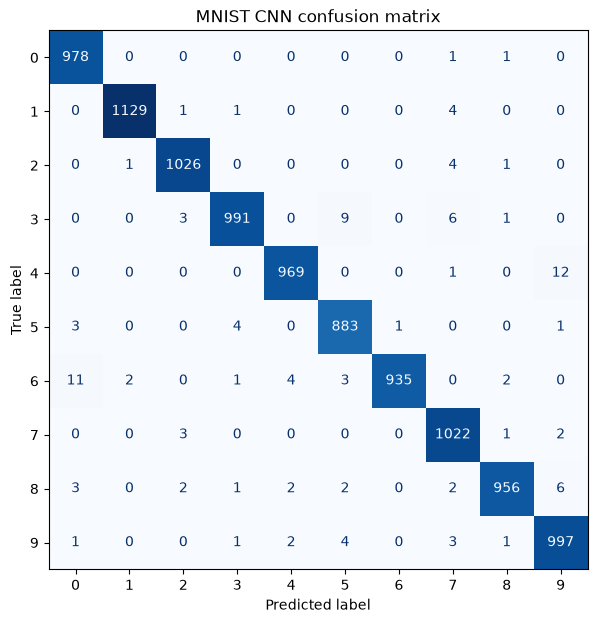

In [13]:
model.eval()
all_predictions = []
all_targets = []
with torch.inference_mode():
    for batch_images, batch_labels in test_loader:
        logits = model(batch_images.to(device))
        all_predictions.extend(logits.argmax(dim=1).cpu().numpy())
        all_targets.extend(batch_labels.numpy())

all_predictions = np.array(all_predictions)
all_targets = np.array(all_targets)
test_accuracy = (all_predictions == all_targets).mean()
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print("\nClassification report:")
print(classification_report(all_targets, all_predictions, digits=4, zero_division=0))

matrix = confusion_matrix(all_targets, all_predictions)
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=np.arange(10))
fig, axis = plt.subplots(figsize=(7, 7))
display.plot(ax=axis, cmap="Blues", colorbar=False)
axis.set_title("MNIST CNN confusion matrix")
plt.show()

## 7. Predictions on unseen test images

The following examples come from the held-out test set and were not used for optimization. Misclassified examples are also displayed for error analysis.


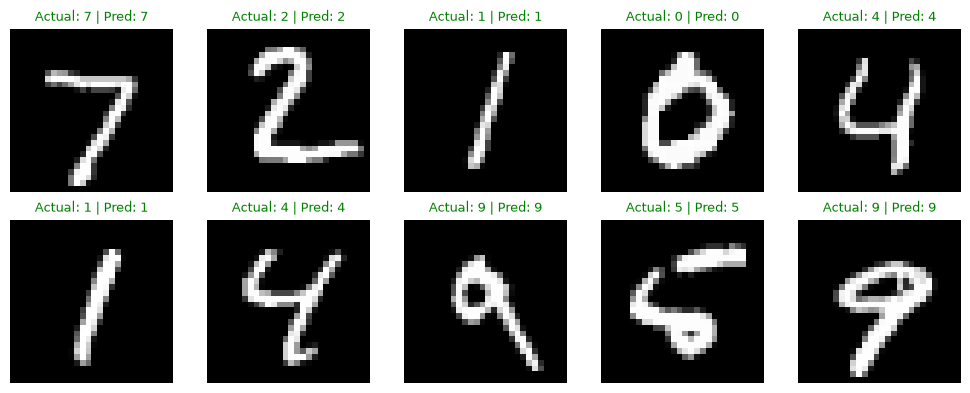

Misclassified test images: 114


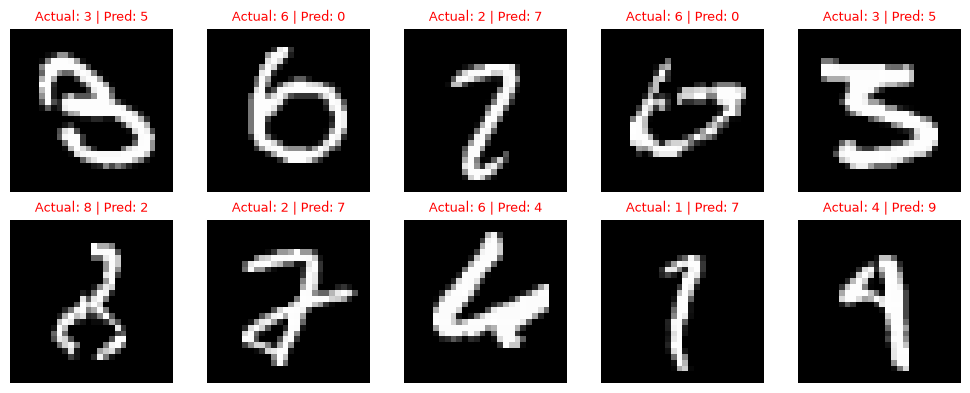

In [14]:
sample_images, sample_labels = next(iter(test_loader))
with torch.inference_mode():
    sample_probabilities = torch.softmax(model(sample_images.to(device)), dim=1)
    sample_predictions = sample_probabilities.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for axis, image, actual, predicted in zip(axes.ravel(), sample_images[:10], sample_labels[:10], sample_predictions[:10]):
    axis.imshow(image.squeeze(), cmap="gray")
    color = "green" if actual.item() == predicted.item() else "red"
    axis.set_title(f"Actual: {actual.item()} | Pred: {predicted.item()}", color=color, fontsize=9)
    axis.axis("off")
plt.tight_layout()
plt.show()

misclassified_indices = np.flatnonzero(all_targets != all_predictions)
print(f"Misclassified test images: {len(misclassified_indices):,}")
if len(misclassified_indices) > 0:
    selected = misclassified_indices[:10]
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for axis, index in zip(axes.ravel(), selected):
        image, actual = test_dataset[int(index)]
        axis.imshow(image.squeeze(), cmap="gray")
        axis.set_title(f"Actual: {actual} | Pred: {all_predictions[index]}", color="red", fontsize=9)
        axis.axis("off")
    plt.tight_layout()
    plt.show()

## 8. Questions and answers

### 1. What is image classification? How does it differ from object detection and image segmentation?

Image classification assigns one or more class labels to an entire image, for example, assigning the label `7` to an MNIST image. Object detection identifies each object and also predicts a bounding box around it. Image segmentation assigns a class to individual pixels, producing precise object or region masks.

### 2. Explain the architecture and working principle of a CNN.

A CNN applies small learnable filters across an image. Early convolutional layers learn edges and simple textures, while deeper layers combine them into digit parts and complete shapes. ReLU introduces non-linearity, pooling reduces spatial dimensions, and fully connected layers use the learned features for final classification. During training, backpropagation and an optimizer adjust the filters to reduce classification loss.

### 3. What is the role of convolutional, pooling, and fully connected layers?

Convolutional layers extract local spatial features while reusing the same filters across the image. Pooling downsamples feature maps, reducing computation and providing limited translation tolerance. Fully connected layers combine the extracted features and map them to the output classes.

### 4. Why is image normalization performed before training?

Normalization puts input values on a consistent numerical scale. This improves gradient stability, usually speeds convergence, and prevents large-valued features from dominating the optimization. Here, MNIST tensors are standardized using mean `0.1307` and standard deviation `0.3081`.

### 5. Explain ReLU and Softmax.

ReLU, $f(x)=\max(0,x)$, adds non-linearity and keeps positive activations while setting negative activations to zero. Softmax converts output logits into a probability distribution whose values sum to one. Cross-entropy loss in this notebook consumes logits directly, and softmax is used only for displayed probabilities.

### 6. What is a confusion matrix?

A confusion matrix is a table in which rows represent actual classes and columns represent predicted classes. Diagonal entries are correct predictions; off-diagonal entries reveal which pairs of classes are confused. It helps identify errors that a single accuracy value hides.

### 7. Differentiate accuracy, precision, recall, and F1-score.

Accuracy is $\frac{TP+TN}{TP+TN+FP+FN}$ and measures all correct decisions. Precision is $\frac{TP}{TP+FP}$ and answers: of the items predicted as a class, how many were correct? Recall is $\frac{TP}{TP+FN}$ and answers: of the actual items in a class, how many were found? F1-score is $2\frac{precision\cdot recall}{precision+recall}$ and balances precision and recall. For example, a digit detector that rarely predicts `8` may have high precision but low recall.

### 8. Compare SIFT/HOG + SVM with CNN classification.

SIFT/HOG + SVM uses manually designed local or gradient features followed by a separate classifier. It can work well with small datasets and limited compute, but its performance depends on feature engineering. A CNN learns both the feature extractor and classifier jointly from data, usually achieving stronger performance on large image datasets while requiring more data, compute, and tuning.

### 9. Mention five real-world applications.

1. Handwritten digit and postal-code recognition.
2. Face identity or emotion classification.
3. Medical image diagnosis support.
4. Defect classification in industrial inspection.
5. Plant disease and crop health recognition.

### 10. How do augmentation, transfer learning, and tuning improve performance?

Data augmentation creates realistic variations such as small rotations, translations, crops, or intensity changes, improving generalization. Transfer learning starts from a model trained on a large dataset and adapts its learned features to the target task, which is useful when labeled data is limited. Hyperparameter tuning searches choices such as learning rate, batch size, architecture depth, dropout, and training epochs to find a better accuracy and generalization trade-off.


## 9. Result analysis and conclusion

The CNN learned useful digit features quickly: training accuracy increased from 93.41% to 98.64%, while validation accuracy reached 98.70%. The final test accuracy, class-wise precision, recall, F1-score, and confusion matrix are reported above. Remaining errors are expected for visually similar or unusually written digits, especially when strokes overlap or are faint.

The experiment shows that CNN-based classification removes the need for handcrafted feature extraction and provides a strong foundation for document processing, OCR, biometric systems, medical imaging, and automated visual inspection. Performance can be improved further with data augmentation, learning-rate scheduling, more epochs, or transfer learning for larger and more complex datasets.
